# CCT College Dublin: Assessment Cover Page

| | |
|---|---|
| Module Title |BSCH20 Sep23 FT Data Visualisation and Communication |
| Assessment Title | CA1 |
| Lecturer Name | Taufique Ahmed |
| Student Full Name | Lucas Alves Ribeiro |
| Student Number | 2023315 |
| Assessment Due Date | 07/11/2026 |
| Date of Submission | 07/11/2026 |

**Declaration:** By submitting this assessment, I confirm that I have read the CCT policy on Academic Misconduct and understand the implications of submitting work that is not my own or does not appropriately reference material taken from a third party or other source. I declare it to be my own work and that all material from third parties has been appropriately referenced. I further confirm that this work has not previously been submitted for assessment by myself or someone else in CCT College Dublin or any other higher education institution.



# Visualising AI, Data Science and Software Development Employment in the USA

## 1. Introduction

This notebook explores employment in occupations related to **Artificial Intelligence (AI), Data Science and Software Development** in the United States. The main dataset is the **Occupational Employment and Wage Statistics (OEWS) "All data" file for May 2023**, published by the U.S. Bureau of Labor Statistics (BLS, 2024). It contains employment counts and wage estimates for every occupation, at national, state, metropolitan and industry level.

**Questions this notebook answers**

1. How many people work in AI related occupations, and how does that compare with software development? *(Visualisation 1)*
2. How much do these occupations pay, and how wide is the pay range inside each one? *(Visualisation 2)*
3. Is there a relationship between the size of an occupation and its pay? *(Visualisation 3)*
4. Where in the USA are AI related jobs concentrated? *(Visualisations 4 and 6)*
5. Which industries employ Data Scientists? *(Visualisation 5)*
6. **Challenge:** how did AI related employment and pay change from 2019 to 2023? *(Visualisations 7, 8 and 9)*

**How "AI employment" is defined here.** The Standard Occupational Classification (SOC) used by the BLS has no single "AI Engineer" code. AI work is spread across several occupations, so this notebook uses a group of occupations as a proxy, split into three categories that are used with the same colour in every chart:

| Category | Occupations (SOC code) | Why |
|---|---|---|
| **AI & Data Science** | Computer and Information Research Scientists (15-1221), Data Scientists (15-2051), Statisticians (15-2041), Operations Research Analysts (15-2031) | Roles that build models, machine learning systems and analytical methods. The BLS describes research scientists as working on areas such as machine learning and AI. |
| **Software Development** | Software Developers (15-1252), Software QA Analysts and Testers (15-1253), Web Developers (15-1254) | Roles that build and deploy software, including AI products. |
| **Supporting Tech** | Computer Systems Analysts (15-1211), Information Security Analysts (15-1212), Database Architects (15-1243), Computer and Information Systems Managers (11-3021) | Roles that design the data infrastructure and manage the teams around AI and software. |

## 2. Setup and data preparation

The libraries used are **pandas** for data handling, and **matplotlib** and **seaborn** for the charts. A fixed colour palette is defined once so that each category keeps the same colour in every chart. The palette was chosen to stay distinguishable for people with colour vision deficiency.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Consistent style for every chart
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85",
    "axes.labelcolor": "#3d3d3a",
    "xtick.color": "#3d3d3a",
    "ytick.color": "#3d3d3a",
    "axes.grid": False,
    "grid.color": "#e6e5e0",
    "legend.frameon": False,
})

# Colour per category (colour-blind safe palette, fixed order)
CAT_COLOURS = {
    "AI & Data Science":    "#2a78d6",   # blue
    "Software Development": "#eb6834",   # orange
    "Supporting Tech":      "#1baf7a",   # aqua
}
GREY = "#8a8a85"
INK = "#3d3d3a"

In [15]:
# Load the May 2023 OEWS "All data" file (about 413,000 rows, takes around a minute)
raw = pd.read_excel("all_data_M_2023.xlsx", sheet_name="All May 2023 data")
print("Rows, columns:", raw.shape)
raw.head(3)

Rows, columns: (413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN


**Cleaning.** The BLS uses special symbols instead of numbers in some cells (see the "Field Descriptions" sheet):

* `*` wage estimate not available
* `**` employment estimate not available
* `#` wage equal to or greater than **$239,200 per year** (the published top limit)

These symbols are converted to missing values (`NaN`) so that the numeric columns can be used in calculations. For `#` a flag is kept, because it means "very high pay", not "unknown".

In [16]:
df = raw.copy()
df.columns = df.columns.str.upper()

num_cols = ["TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "PCT_TOTAL", "A_MEAN",
            "A_PCT10", "A_PCT25", "A_MEDIAN", "A_PCT75", "A_PCT90"]

TOP_CODE = 239200   # value represented by '#'
df["A_PCT90_TOPCODED"] = df["A_PCT90"].astype(str).str.strip().eq("#")
df["A_PCT75_TOPCODED"] = df["A_PCT75"].astype(str).str.strip().eq("#")

for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")   # '*', '**', '#' -> NaN

# Focus occupations and their category
OCCS = {
    "15-1221": ("Computer & Info Research Scientists", "AI & Data Science"),
    "15-2051": ("Data Scientists",                     "AI & Data Science"),
    "15-2041": ("Statisticians",                       "AI & Data Science"),
    "15-2031": ("Operations Research Analysts",        "AI & Data Science"),
    "15-1252": ("Software Developers",                 "Software Development"),
    "15-1253": ("Software QA Analysts & Testers",      "Software Development"),
    "15-1254": ("Web Developers",                      "Software Development"),
    "15-1211": ("Computer Systems Analysts",           "Supporting Tech"),
    "15-1212": ("Information Security Analysts",       "Supporting Tech"),
    "15-1243": ("Database Architects",                 "Supporting Tech"),
    "11-3021": ("Computer & IS Managers",              "Supporting Tech"),
}

# National, cross-industry estimates (one row per occupation for the whole USA)
national = df[(df["AREA_TYPE"] == 1) & (df["I_GROUP"] == "cross-industry")]
all_occ = national[national["OCC_CODE"] == "00-0000"].iloc[0]

nat = national[national["OCC_CODE"].isin(OCCS)].copy()
nat["Occupation"] = nat["OCC_CODE"].map(lambda c: OCCS[c][0])
nat["Category"]   = nat["OCC_CODE"].map(lambda c: OCCS[c][1])

print(f"All occupations in the USA (May 2023): {all_occ['TOT_EMP']:,.0f} jobs, "
      f"median annual wage ${all_occ['A_MEDIAN']:,.0f}")
nat[["OCC_CODE", "Occupation", "Category", "TOT_EMP", "A_MEDIAN", "A_MEAN"]] \
    .sort_values("TOT_EMP", ascending=False).reset_index(drop=True)

All occupations in the USA (May 2023): 151,853,870 jobs, median annual wage $48,060


,OCC_CODE,Occupation,Category,TOT_EMP,A_MEDIAN,A_MEAN
0,15-1252,Software Developers,Software Development,1656880.0,132270.0,138110.0
1,11-3021,Computer & IS Managers,Supporting Tech,592600.0,169510.0,180720.0
2,15-1211,Computer Systems Analysts,Supporting Tech,498810.0,103800.0,110800.0
3,15-1253,Software QA Analysts & Testers,Software Development,203040.0,101800.0,108460.0
4,15-2051,Data Scientists,AI & Data Science,192710.0,108020.0,119040.0
5,15-1212,Information Security Analysts,Supporting Tech,175350.0,120360.0,124740.0
6,15-2031,Operations Research Analysts,AI & Data Science,117880.0,83640.0,95600.0
7,15-1254,Web Developers,Software Development,85350.0,84960.0,95570.0
8,15-1243,Database Architects,Supporting Tech,59920.0,134700.0,137030.0
9,15-1221,Computer & Info Research Scientists,AI & Data Science,35210.0,145080.0,157160.0


## 3. Visualisations of the May 2023 data

### Visualisation 1: Employment by occupation (horizontal bar chart)

**Objective:** *comparison.* Compare how many people work in each AI, data and software occupation in the USA, and see how big the AI & Data Science group is next to software development.

**Why this chart:** the data is one **categorical** variable (occupation) and one **numeric** variable (employment). A bar chart is the clearest way to compare magnitudes because the eye compares bar lengths very accurately. Bars are **horizontal** so that the long occupation names can be read without rotating them, and they are **sorted** so the ranking is visible at once. Colour shows the category.

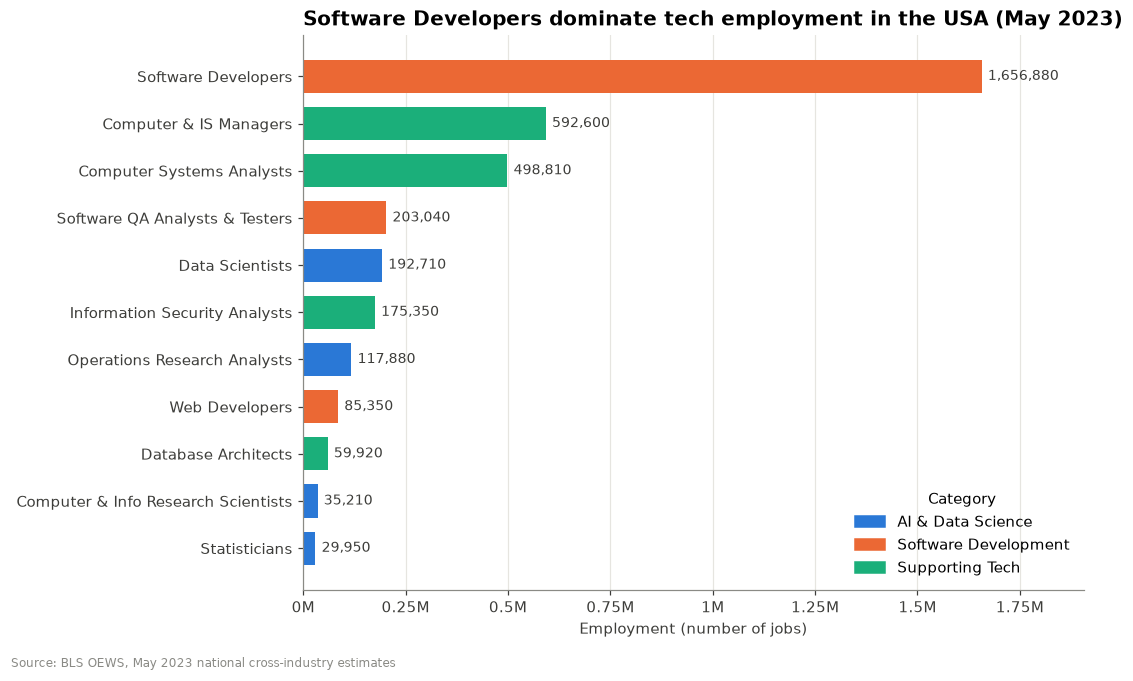

Category
Software Development    1,945,270
Supporting Tech         1,326,680
AI & Data Science         375,750


In [17]:
v1 = nat.sort_values("TOT_EMP")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(v1["Occupation"], v1["TOT_EMP"],
               color=v1["Category"].map(CAT_COLOURS), height=0.7)

for bar, val in zip(bars, v1["TOT_EMP"]):
    ax.text(bar.get_width() + 15000, bar.get_y() + bar.get_height() / 2,
            f"{val:,.0f}", va="center", fontsize=9, color=INK)

ax.xaxis.set_major_locator(mtick.MultipleLocator(250000))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e6:g}M"))
ax.set_xlim(0, v1["TOT_EMP"].max() * 1.15)
ax.set_xlabel("Employment (number of jobs)")
ax.set_title("Software Developers dominate tech employment in the USA (May 2023)")
ax.grid(axis="x")
ax.set_axisbelow(True)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_COLOURS.values()]
ax.legend(handles, CAT_COLOURS.keys(), loc="lower right", title="Category")
fig.text(0.01, -0.02, "Source: BLS OEWS, May 2023 national cross-industry estimates", fontsize=8, color=GREY)
plt.tight_layout()
plt.show()

totals = nat.groupby("Category")["TOT_EMP"].sum().sort_values(ascending=False)
print((totals.map("{:,.0f}".format)).to_string())

**What I learned about AI employment:**

* Every occupation in the chart pays well above the median of all US jobs (**$48,060**). Even the lowest paid 10% of most of these roles earn close to or above that national median.
* Among the AI roles, **Computer and Information Research Scientists** have the highest median pay of the non managerial roles (**about $145,000**), and their 90th percentile reaches about **$233,000**. Specialist AI research skills are paid at a premium.
* **Data Scientists** have a median of about **$108,000**, lower than Software Developers (about **$132,000**). So data science is a well paid entry into AI, but at the national level it does not pay more than software engineering.
* The boxes are wide. For Data Scientists the 90th percentile is about **three times** the 10th percentile, which suggests that experience, seniority and location make a big difference to pay in AI related careers.